# Do retail discounts pay for themselves?

A walkthrough of the analysis in this repository, from raw tables to a recommendation. Every number below is computed live from the source data by the functions in `src/`, so the notebook cannot drift away from the code.

**The question.** About half of all sales in this retailer's data carry a discount. Do those discounts earn their cost, in extra units, extra customers or extra profit?

**How to read it.** Each section poses a question, runs the check and says what it means. The data itself is not in the repository (it is gitignored), and this notebook only shows aggregated results, never individual transactions.

In [1]:
import sys
import tempfile
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display

# Find the project root (the folder holding pyproject.toml) so that `import src...` works from anywhere.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt

from src.analysis.breakeven import breakeven_table, discount_cost_summary, nominal_depth
from src.analysis.diagnostics import run_promo_diagnostics
from src.analysis.pooled_elasticity import estimate_pooled_elasticity, pooled_elasticity_by_group
from src.analysis.scenarios import DEFAULT_CAPS, breakeven_elasticity, scenario_grid
from src.data.cleaning import clean_fact_sales, qa_summary_to_markdown
from src.data.loader import load_all
from src.features.build_features import build_sales_analysis_table
from src.visualization import plot_breakeven_gap, plot_elasticity_estimates, plot_scenario_curves

FIG_DIR = Path(tempfile.mkdtemp())  # charts are drawn here and shown below; nothing is written into the repo

## 1. Load and clean the data

The data is a star schema: one sales table (`fact_sales`) and four dimension tables (customers, dates, products, stores). Real point-of-sale data is messy, so `clean_fact_sales` follows one rule: **it never silently drops a row**. Exact duplicates are removed; everything else that looks wrong is flagged with a reason and excluded only from the aggregates, so every exclusion stays auditable. Returns (negative quantities) are a different event from errors and are kept apart. A discount larger than the sale itself would make net sales negative on an ordinary sale, which is a data error and not a promotion, so it is flagged too.

In [2]:
tables = load_all()
sales_clean, qa = clean_fact_sales(
    tables["sales"], tables["customer"], tables["product"], tables["store"], tables["date"]
)
analysis = build_sales_analysis_table(sales_clean, tables["customer"], tables["store"], tables["date"])
analysis["year_week"] = analysis["year"].astype(str) + "-" + analysis["week"].astype(str)

display(
    Markdown(
        f"**{qa.total_rows_raw:,}** raw rows, **{qa.duplicate_rows_removed:,}** duplicates removed, "
        f"**{qa.total_invalid_rows:,}** more flagged as invalid. That leaves **{len(analysis):,}** valid sales "
        f"to analyse (the **{qa.return_rows:,}** returns are kept apart)."
    )
)
display(Markdown(qa_summary_to_markdown(qa)))

**120,680** raw rows, **680** duplicates removed, **1,041** more flagged as invalid. That leaves **118,664** valid sales to analyse (the **296** returns are kept apart).

| Metric | Value |
|---|---|
| Raw rows | 120,680 |
| Duplicate rows removed | 680 |
| Rows after dedup | 120,000 |
| Invalid: bad product FK | 149 |
| Invalid: bad store FK | 100 |
| Invalid: missing date | 150 |
| Invalid: date outside calendar | 100 |
| Invalid: zero quantity | 199 |
| Invalid: non-positive price | 150 |
| Invalid: discount exceeds gross sale | 345 |
| **Total invalid rows (excluded from aggregates)** | **1,041** |
| **Total valid rows** | **118,959** |
| Return rows (kept, analyzed separately) | 296 |
| Missing customer_id | 599 |
| Customer_id not in dim_customer | 150 |
| QA mismatch: gross_sales (source vs recomputed) | 891 |
| QA mismatch: net_sales (source vs recomputed) | 839 |
| QA mismatch: cost_amount (source vs recomputed) | 495 |
| QA mismatch: profit_amount (source vs recomputed) | 1,087 |
| QA mismatch: gross_margin_pct (source vs recomputed) | 607 |

## 2. Can this data answer the question at all?

Before measuring any promotion effect, check whether the data can support one. Three questions:

- How much of the calendar is empty? A daily average silently ignores every day without a sale.
- Is discounting targeted? A real promotional calendar favours some categories, stores, weekdays and months.
- Does discounting come in campaigns? A product on promotion today should still be on promotion for its next sale.

In [3]:
diagnostics = run_promo_diagnostics(analysis)
sparsity, persistence = diagnostics["sparsity"], diagnostics["persistence"]

display(
    Markdown(
        f"- **{diagnostics['promo_share_pct']}%** of sales carry a discount.\n"
        f"- **{sparsity['pct_sku_days_zero_sales']}%** of product-days have no sales at all, and a product-day with "
        f"sales averages {sparsity['avg_txns_per_active_sku_day']} sales.\n"
        f"- A product discounted on one sale is discounted on its next sale **{persistence['p_promo_after_promo']:.1%}** "
        f"of the time, against **{persistence['p_promo_after_nonpromo']:.1%}** after a full-price sale."
    )
)
display(Markdown("**Share of sales discounted, by dimension**"))
diagnostics["assignment"]

- **54.7%** of sales carry a discount.
- **72.3%** of product-days have no sales at all, and a product-day with sales averages 1.17 sales.
- A product discounted on one sale is discounted on its next sale **54.4%** of the time, against **55.1%** after a full-price sale.

**Share of sales discounted, by dimension**

,dimension,min_promo_share_pct,max_promo_share_pct,spread_pts
0,category,54.3,55.5,1.2
1,region,54.6,54.9,0.3
2,store_type,54.7,54.8,0.2
3,day_name,54.3,55.2,0.9
4,month,54.2,55.7,1.5
5,customer_segment,54.5,54.9,0.3


**What this means.** If discounts were planned promotions, the share would differ by category, weekday and month, and it would persist from one sale to the next. A flat share with no persistence means discounting behaves like a routine decision at the till, not like campaigns. There are no "promotion periods" to compare with normal periods, which limits what this data can prove (section 6 comes back to it).

## 3. Do discounts change what customers buy?

Compare units per sale and profit per sale at each discount depth. Discounts are stored to the cent, so a 5% discount appears as 4.99% or 5.01%; `nominal_depth` snaps each one to its real level.

,sales,units_per_sale,profit_per_sale
discount,,,
None,53736,3.01,1732.41
5%,29538,3.00,1406.23
10%,21248,3.00,1092.01
15%,9370,3.01,776.41
20%,4772,3.01,458.61


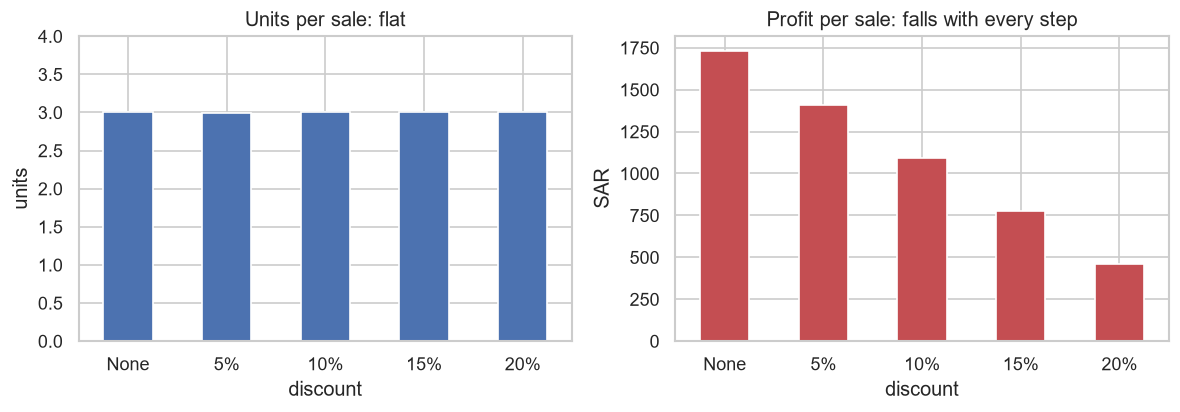

In [4]:
analysis["depth"] = nominal_depth(analysis["discount_pct"])
by_depth = analysis.groupby("depth").agg(
    sales=("quantity", "size"),
    units_per_sale=("quantity", "mean"),
    profit_per_sale=("profit_amount", "mean"),
)
by_depth.index = ["None" if d == 0 else f"{d:.0%}" for d in by_depth.index]
by_depth.index.name = "discount"
display(by_depth.round(2))

fig, (ax_units, ax_profit) = plt.subplots(1, 2, figsize=(10, 3.6))
by_depth["units_per_sale"].plot.bar(ax=ax_units, color="#4C72B0", rot=0)
ax_units.set(title="Units per sale: flat", ylabel="units", ylim=(0, 4), xlabel="discount")
by_depth["profit_per_sale"].plot.bar(ax=ax_profit, color="#C44E52", rot=0)
ax_profit.set(title="Profit per sale: falls with every step", ylabel="SAR", xlabel="discount")
fig.tight_layout()

Customers buy the same quantity at every discount depth, while profit per sale drops at every step. To make sure that is not an accident of busy weeks or particular stores, estimate the **price elasticity**: by how many percent quantity changes when price changes by 1%. The estimate pools all products, giving each its own baseline (a product fixed effect), with standard errors that respect the grouping by product. An elasticity of **-1** would mean a 1% price cut brings 1% more units, the yardstick for the table below.

,specification,elasticity,ci_low,ci_high,n_obs
0,SKU effects,-0.003,-0.049,0.042,118664
1,SKU + week effects,-0.004,-0.050,0.041,118664
2,SKU + store effects,-0.003,-0.049,0.042,118664


**Reading it:** a 10% price cut changes quantity by about **+0.03%**. Every interval, overall and in each of the 7 categories, excludes -1: **True**.

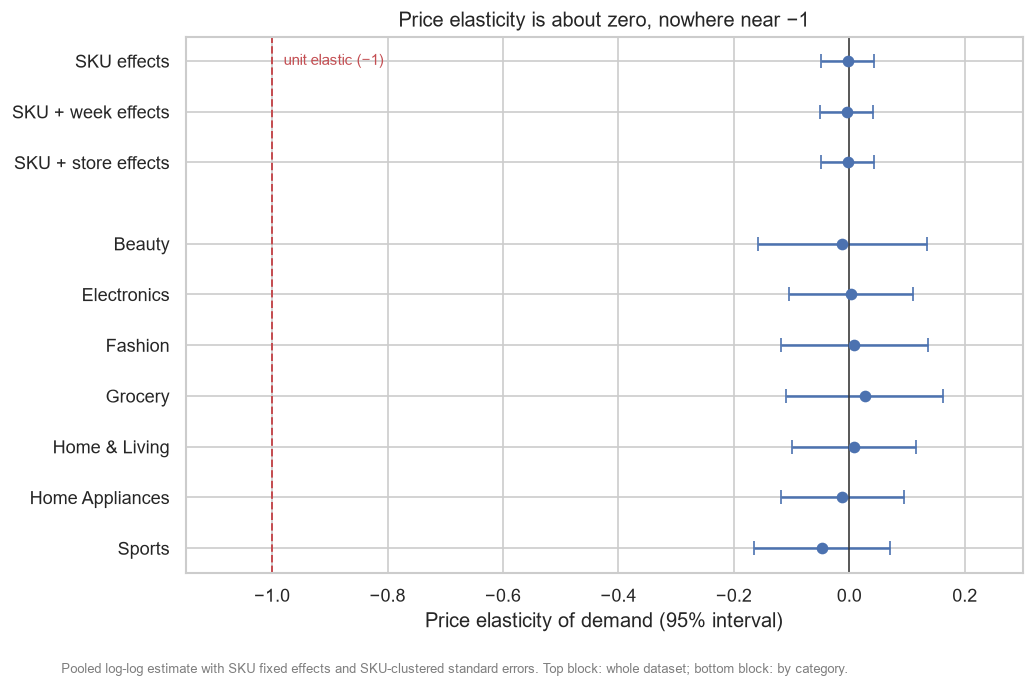

In [5]:
specifications = {
    "SKU effects": ("product_id",),
    "SKU + week effects": ("product_id", "year_week"),
    "SKU + store effects": ("product_id", "store_id"),
}
pooled = pd.DataFrame(
    [{"specification": name, **estimate_pooled_elasticity(analysis, fixed_effects=fe)} for name, fe in specifications.items()]
)
by_category = pooled_elasticity_by_group(analysis, "category", n_jobs=1)

display(pooled[["specification", "elasticity", "ci_low", "ci_high", "n_obs"]])
excludes_minus_one = bool((pooled["ci_low"] > -1).all() and (by_category["ci_low"] > -1).all())
display(
    Markdown(
        f"**Reading it:** a 10% price cut changes quantity by about **{-0.10 * pooled['elasticity'].iloc[0]:+.2%}**. "
        f"Every interval, overall and in each of the {len(by_category)} categories, excludes -1: **{excludes_minus_one}**."
    )
)
display(Image(filename=plot_elasticity_estimates(pooled, by_category, FIG_DIR)))

## 4. What would a discount need to deliver?

With a margin of *m* at full price, a discount of depth *d* leaves a profit of *(m - d)* per unit of list price instead of *m*. Volume must therefore rise by **d / (m - d)** just to keep total profit flat. The module computes this in dollars (`discount given / profit actually earned`), which stays exact when a band mixes products with different margins, and sets it against the lift actually observed in units per sale.

Discounts cost **37.3M SAR**, equal to **22.3%** of the 167.3M SAR profit. **2,046** discounted sales (3.2% of them) were priced at or below cost.

,sales,margin at full price (%),volume lift needed (%),observed lift in units per sale (%),sales at or below cost,share at or below cost (%)
discount,,,,,,
5%,29538,27.3,22.4,-0.30,0,0.0
10%,21248,27.3,57.7,-0.09,101,0.5
15%,9370,27.4,120.6,0.13,809,8.6
20%,4772,27.4,268.7,-0.04,1136,23.8


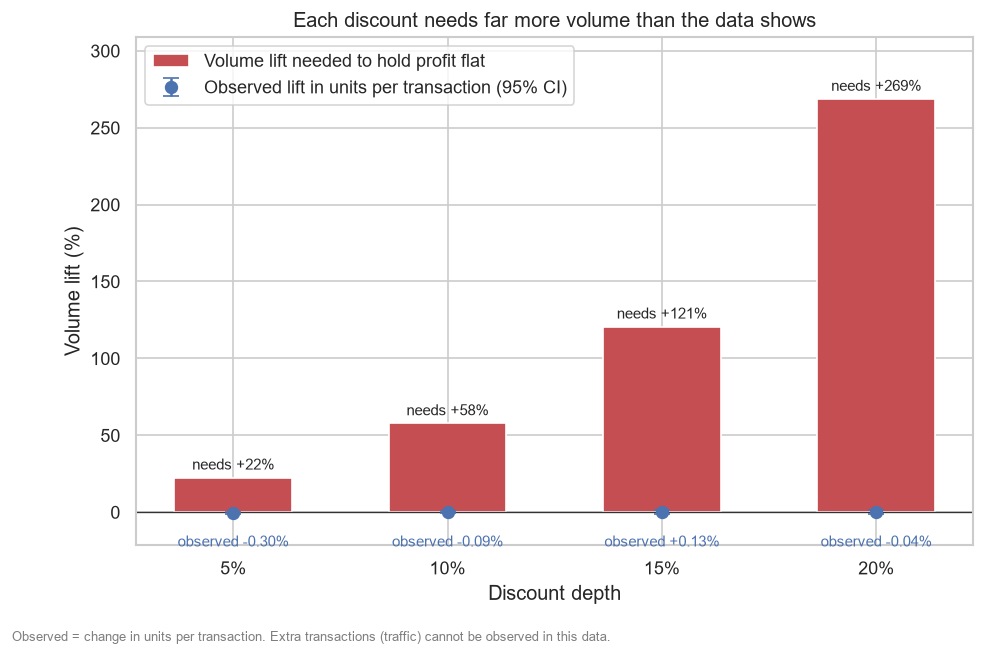

In [6]:
breakeven = breakeven_table(analysis)
cost = discount_cost_summary(analysis)

display(
    Markdown(
        f"Discounts cost **{cost['total_discount_given'] / 1e6:.1f}M SAR**, equal to **{cost['discount_pct_of_profit']}%** "
        f"of the {cost['total_profit'] / 1e6:.1f}M SAR profit. **{cost['below_cost_txns']:,}** discounted sales "
        f"({cost['below_cost_share_of_promo_pct']}% of them) were priced at or below cost."
    )
)
shown = breakeven.assign(discount=breakeven["depth"].map("{:.0%}".format)).set_index("discount")[
    [
        "txns",
        "full_price_margin_pct",
        "required_volume_lift_pct",
        "observed_qty_lift_pct",
        "below_cost_txns",
        "below_cost_share_pct",
    ]
].rename(
    columns={
        "txns": "sales",
        "full_price_margin_pct": "margin at full price (%)",
        "required_volume_lift_pct": "volume lift needed (%)",
        "observed_qty_lift_pct": "observed lift in units per sale (%)",
        "below_cost_txns": "sales at or below cost",
        "below_cost_share_pct": "share at or below cost (%)",
    }
)
display(shown)
display(Image(filename=plot_breakeven_gap(breakeven, FIG_DIR)))

## 5. What would a discount cap do?

A cap leaves every sale discounted at or below the cap untouched and re-prices deeper discounts to the cap; volume then reacts according to an assumed elasticity. The data cannot measure customers who stop coming altogether, so the result is shown across a range of reactions, together with the **break-even elasticity**: the strongest reaction at which the cap still adds profit.

**Profit change versus today, million SAR**

,elasticity 0,elasticity -0.05,elasticity -0.5,elasticity -1,elasticity -2,elasticity -3
cap,,,,,,
No discounts,37.3,36.8,32.1,27.1,18.1,10.0
5%,16.9,16.7,14.9,13.0,9.3,6.1
10%,5.9,5.8,5.3,4.7,3.7,2.7
15%,1.5,1.5,1.4,1.3,1.1,0.9


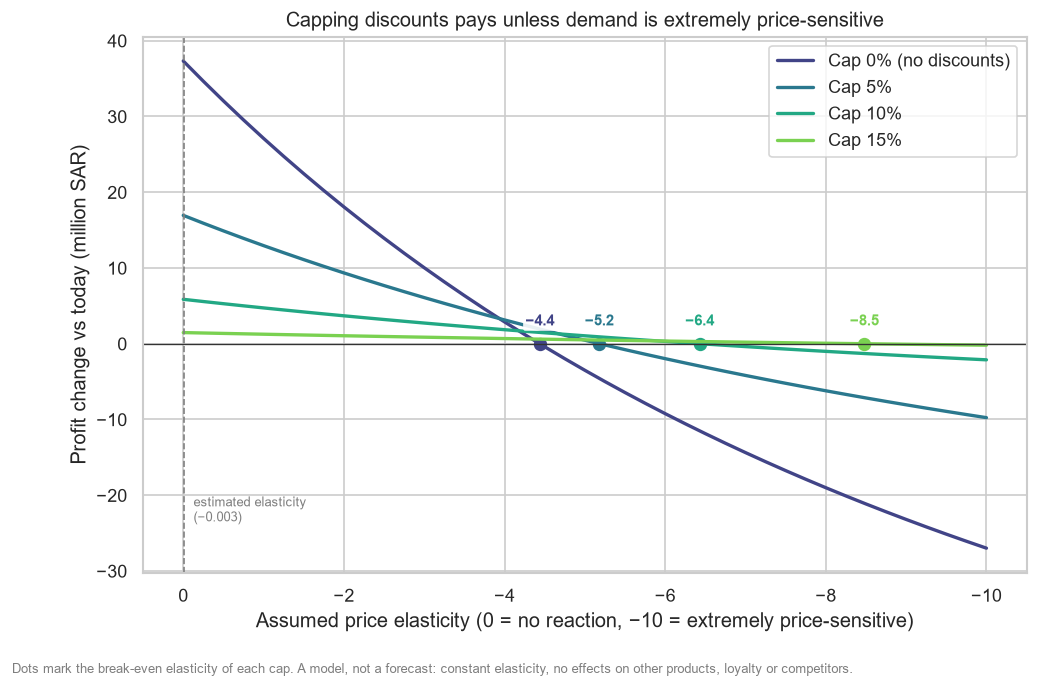

In [7]:
grid = scenario_grid(analysis)
profit_change = (grid.pivot(index="cap", columns="elasticity", values="profit_change") / 1e6).round(1)
profit_change = profit_change[sorted(profit_change.columns, reverse=True)]  # from "no reaction" to "strong reaction"
profit_change.index = ["No discounts" if c == 0 else f"{c:.0%}" for c in profit_change.index]
profit_change.index.name = "cap"
profit_change.columns = [f"elasticity {e:g}" for e in profit_change.columns]
display(Markdown("**Profit change versus today, million SAR**"))
display(profit_change)

breakeven_elast = pd.DataFrame(
    [{"cap": cap, "breakeven_elasticity": round(breakeven_elasticity(analysis, cap), 2)} for cap in DEFAULT_CAPS]
)
curve = scenario_grid(analysis, DEFAULT_CAPS, tuple(np.round(np.arange(0.0, -10.01, -0.25), 2)))
display(Image(filename=plot_scenario_curves(curve, breakeven_elast, FIG_DIR)))

## 6. What this means

**What the data supports.** Quantity per sale does not respond to discounts at any depth, so each discount is margin given away unless it also brings in extra customers.

In [8]:
cap10 = grid[grid["cap"] == 0.10].set_index("elasticity")
breakeven_10 = breakeven_elast.set_index("cap").loc[0.10, "breakeven_elasticity"]
display(
    Markdown(
        f"A **10% cap** would touch {cap10['share_of_promo_txns_affected_pct'].iloc[0]}% of discounted sales. "
        f"If customers do not react it adds **{cap10.loc[0.0, 'profit_change'] / 1e6:+.1f}M SAR** "
        f"({cap10.loc[0.0, 'profit_change_pct']:+.1f}% of profit). If they react strongly (elasticity -3) it still adds "
        f"**{cap10.loc[-3.0, 'profit_change'] / 1e6:+.1f}M SAR**, though net sales would fall by "
        f"{-cap10.loc[-3.0, 'net_sales_change'] / 1e6:.1f}M SAR. It stops paying only if customers are more "
        f"price-sensitive than **{breakeven_10}**."
    )
)

A **10% cap** would touch 21.8% of discounted sales. If customers do not react it adds **+5.9M SAR** (+3.5% of profit). If they react strongly (elasticity -3) it still adds **+2.7M SAR**, though net sales would fall by 10.3M SAR. It stops paying only if customers are more price-sensitive than **-6.43**.

**What the data cannot tell.** Whether discounts bring in *more customers*. These results measure how much each customer buys, not how many come. With no promotion calendar and discounts applied sale by sale, discounted periods cannot be compared with comparable undiscounted periods. This is the main uncertainty, and the reason for a test instead of a blanket change.

**Recommended next steps** (details in [`STAKEHOLDER_SUMMARY.md`](../STAKEHOLDER_SUMMARY.md)):

1. Stop discounts that sell at or below cost.
2. Test a 10% cap in half of the stores for 8 to 12 weeks, comparing the number of sales, units and profit per store-week against matched stores.
3. Record promotions properly (product, store, dates, planned discount), so the next analysis can measure effects on customer traffic directly.
4. Ask the data team about the data issues flagged in section 1.

*Reproduce:* `python -m src.pipeline` writes every table and chart used here to `outputs/`. To re-run this notebook, install `ipykernel`, pick the project's virtual environment as the kernel, and choose Run All.